# Session 7: Vertical resolution, vertical errors and aircraft mass

**Question:** do the Session 4–6 conclusions hold with finer vertical data, errors in the height of the moist layer, and different aircraft weights?

**Builds on:** Sessions 4–6 found that climbing to FL370 or above removed contrail exposure in every scenario tested, and that the minimum-fuel route was already contrail-free. Both findings had untested weak points: FL370–FL380 lie between two ERA5 levels, where values are interpolated across the tropopause; no scenario moved the moist layer up or down; and the aircraft mass was the model's own estimate.

**Approach:**
1. Reload ERA5 on 10 pressure levels (175–300 hPa, every 10 hPa between 190 and 250 hPa), compare with the 5-level data, and add FL390.
2. Move the whole field up or down by 150, 300 and 600 m and re-evaluate the FL340–FL390 routes.
3. Recompute fuel for start-of-cruise masses of 56 t, the model estimate (≈64 t), 68 t and 72 t, flagging routes outside the flight envelope.
4. Re-run the deterministic vs robust route choice for each mass across the vertical scenarios.
5. Investigate a fuel discrepancy with Session 4 and correct Sessions 4–6.

**Assumptions:** as Session 4, with 45 routes (5 lateral offsets × FL310–FL390). From this session on, reusable logic lives in `src/contrail_routing/` (`config`, `scenarios`, `performance`, `decisions`); this notebook only calls it.

**Sections:** 1. Setup · 2. Coarse vs fine vertical levels · 3. Vertical displacement · 4. Fuel and aircraft mass · 5. Route choice by mass · 6. Fuel discrepancy and correction to Sessions 4–6 · 7. Summary figures · Results

## 1. Setup

The 45 routes are built from the shared case definition in `contrail_routing.config`.

In [1]:
import sys, warnings
from pathlib import Path
SRC = (Path("..") / "src").resolve()
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pycontrails.physics import thermo, units

from contrail_routing import config
from contrail_routing.met import load_era5_checked, load_region
from contrail_routing.scenarios import shift_field, coverage, run_scenarios, pcr_by_scenario
from contrail_routing.performance import fuel_table
from contrail_routing.decisions import choose, pareto_with_marginal

warnings.filterwarnings("ignore", message=r"\s*Met data appears to have originated from ECMWF")

results_dir = Path("..") / "results"
fig_dir = results_dir / "figures"
s7_dir = results_dir / "session7"
s7_dir.mkdir(parents=True, exist_ok=True)

FLIGHT_LEVELS_7 = config.FLIGHT_LEVELS + [390]
specs_all = config.route_specs(flight_levels=FLIGHT_LEVELS_7)
specs_df = pd.DataFrame.from_dict(specs_all, orient="index")
routes_all = config.build_routes(specs_all)
print(len(routes_all), "routes: flight levels", FLIGHT_LEVELS_7, "x offsets", config.OFFSETS_KM)

45 routes: flight levels [310, 320, 330, 340, 350, 360, 370, 380, 390] x offsets [-300, -150, 0, 150, 300]


## 2. Coarse vs fine vertical levels

The coarse (5-level) data loads from the cache built in Session 2. The fine
(10-level) data is new: **the first run downloads and converts it hour by hour
and can take 10–20 minutes**. Close other heavy programs (especially browsers)
while it runs. After that it loads from the cache in seconds.

If an hour fails to convert (as happened in Session 2), `load_era5_checked`
finds the empty hour, deletes it from the cache and rebuilds it automatically.

In [2]:
# Each load checks every hour for missing values and rebuilds any bad cached hour
met_coarse, report_coarse = load_era5_checked(config.ERA5_TIME, config.LEVELS_COARSE,
                                              config.REGION_LON, config.REGION_LAT)
met_fine, report_fine = load_era5_checked(config.ERA5_TIME, config.LEVELS_FINE,
                                          config.REGION_LON, config.REGION_LAT)
print(report_fine.to_string(index=False))

region_coarse = load_region(met_coarse, config.REGION_LON, config.REGION_LAT)
region_fine = load_region(met_fine, config.REGION_LON, config.REGION_LAT)
print("Coarse levels (hPa):", region_coarse.data["level"].values)
print("Fine levels (hPa):  ", region_fine.data["level"].values)

ERA5 [200, 225, 250, 275, 300] hPa: all 7 hours complete.
ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
 attempt bad_hours
       0        []
Coarse levels (hPa): [200. 225. 250. 275. 300.]
Fine levels (hPa):   [175. 190. 200. 210. 220. 230. 240. 250. 275. 300.]


In [3]:
cov_coarse = coverage(region_coarse, routes_all)
cov_fine = coverage(region_fine, routes_all)
print("Routes outside the coarse data:", cov_coarse.index[~cov_coarse["ok"]].tolist())
assert cov_fine["ok"].all(), "Some routes are outside the fine data"

routes_coarse = {n: r for n, r in routes_all.items() if cov_coarse.at[n, "ok"]}
res_base = run_scenarios({"coarse": region_coarse}, routes_coarse, s7_dir, "base")
res_base |= run_scenarios({"fine": region_fine}, routes_all, s7_dir, "base")
pcr_res = pcr_by_scenario(res_base, specs_all)

# Regression: the coarse region must reproduce Session 4 exactly
m4 = pd.read_csv(results_dir / "session4_route_metrics.csv").set_index("route")
diff = (pcr_res["coarse"].dropna() - m4["pcr_km"]).abs().max()
print(f"\nMax |coarse - Session 4| pcr_km: {diff:.6f}")
assert diff < 1e-6
print("Coarse data reproduces Session 4.")

pcr_res = pcr_res.join(specs_df[["flight_level", "offset_km"]])
for col in ["coarse", "fine"]:
    print(f"\nDistance in PCR (km), {col} levels:")
    print(pcr_res.pivot(index="flight_level", columns="offset_km", values=col).round(0))
pcr_res.to_csv(results_dir / "session7_pcr_coarse_vs_fine.csv")

Routes outside the coarse data: ['SE300_FL390', 'SE150_FL390', 'GC0_FL390', 'NW150_FL390', 'NW300_FL390']
coarse           loaded from disk
fine             loaded from disk

Max |coarse - Session 4| pcr_km: 0.000000
Coarse data reproduces Session 4.

Distance in PCR (km), coarse levels:
offset_km       -300    -150     0      150    300
flight_level                                      
310           1049.0  1421.0  1587.0  787.0  869.0
320            731.0  1090.0  1173.0  331.0  566.0
330           1007.0  1311.0  1518.0  414.0  483.0
340            814.0  1035.0  1035.0  373.0  276.0
350            994.0  1256.0   856.0  248.0   97.0
360            911.0  1063.0   400.0   69.0   41.0
370              0.0     0.0     0.0    0.0    0.0
380              0.0     0.0     0.0    0.0    0.0
390              NaN     NaN     NaN    NaN    NaN

Distance in PCR (km), fine levels:
offset_km       -300    -150     0      150    300
flight_level                                      
310         

Coarse:
            issr_fraction  rhi_max
level_hPa                        
200.0              0.000    0.960
225.0              0.085    1.318
250.0              0.139    1.355
275.0              0.174    1.399
300.0              0.195    1.496 

Fine:
            issr_fraction  rhi_max
level_hPa                        
175.0              0.000    0.165
190.0              0.000    0.548
200.0              0.000    0.960
210.0              0.025    1.212
220.0              0.069    1.261
230.0              0.109    1.329
240.0              0.125    1.338
250.0              0.139    1.355
275.0              0.174    1.399
300.0              0.195    1.496


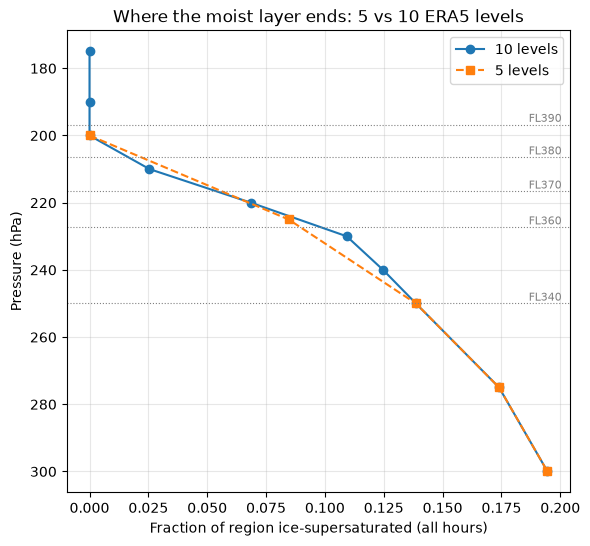

In [4]:
def issr_profile(region):
    """Fraction of the region (all hours) that is ice-supersaturated, and max RHi, by level."""
    d = region.data
    temp = d["air_temperature"].transpose("longitude", "latitude", "level", "time").values
    q = d["specific_humidity"].transpose("longitude", "latitude", "level", "time").values
    p = d["level"].values[None, None, :, None] * 100.0
    rhi = thermo.rhi(q, temp, p)
    return pd.DataFrame({"issr_fraction": (rhi > 1.0).mean(axis=(0, 1, 3)),
                         "rhi_max": rhi.max(axis=(0, 1, 3))},
                        index=pd.Index(d["level"].values, name="level_hPa"))

prof_coarse, prof_fine = issr_profile(region_coarse), issr_profile(region_fine)
print("Coarse:\n", prof_coarse.round(3), "\n\nFine:\n", prof_fine.round(3))

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot(prof_fine["issr_fraction"], prof_fine.index, "o-", label="10 levels")
ax.plot(prof_coarse["issr_fraction"], prof_coarse.index, "s--", label="5 levels")
for fl in [340, 360, 370, 380, 390]:
    p_fl = float(units.m_to_pl(units.ft_to_m(fl * 100.0)))
    ax.axhline(p_fl, color="grey", linewidth=0.8, linestyle=":")
    ax.annotate(f"FL{fl}", (ax.get_xlim()[1], p_fl), xytext=(-30, 2),
                textcoords="offset points", fontsize=8, color="grey")
ax.invert_yaxis()
ax.set_xlabel("Fraction of region ice-supersaturated (all hours)")
ax.set_ylabel("Pressure (hPa)")
ax.set_title("Where the moist layer ends: 5 vs 10 ERA5 levels")
ax.legend()
ax.grid(alpha=0.3)
fig.savefig(fig_dir / "session7_issr_profile_coarse_vs_fine.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Vertical displacement

Pressure levels are relabelled so the entire temperature and humidity field moves
up or down (`shift_field(up_m=...)`), with relative humidity carried along with
the air. Only FL340–FL390 are evaluated: the largest shifts move the data's
lowest level above FL310–FL330.

*Correction:* a first version (`results/session7/vertical_*.csv`) kept specific
humidity fixed while changing pressure, which also dried the field when moving
it up (≈9% at 600 m) and moistened it when moving it down. Results below
(`vertical_v2_*`) keep relative humidity unchanged.

In [5]:
VERTICAL_M = {"base": 0.0, "up150": 150.0, "up300": 300.0, "up600": 600.0,
              "down150": -150.0, "down300": -300.0, "down600": -600.0}
specs_v = {n: s for n, s in specs_all.items() if s["flight_level"] >= 340}
routes_v = {n: routes_all[n] for n in specs_v}

scen_v = {name: shift_field(region_fine, up_m=dz) for name, dz in VERTICAL_M.items()}
for name, met in scen_v.items():
    cov = coverage(met, routes_v)
    assert cov["ok"].all(), f"{name}: routes outside shifted data: {cov.index[~cov['ok']].tolist()}"
print("All shifted fields cover all FL340-FL390 routes.")

res_v = run_scenarios(scen_v, routes_v, s7_dir, "vertical_v2")
pcr_v = pcr_by_scenario(res_v, specs_all)
assert np.allclose(pcr_v["base"], pcr_res.loc[pcr_v.index, "fine"])
print("Zero shift reproduces the fine-level results.")

key_v = ["GC0_FL390", "GC0_FL380", "GC0_FL370", "GC0_FL360", "NW150_FL360",
         "NW300_FL360", "GC0_FL350", "GC0_FL340", "NW150_FL340"]
print("\nPCR km under vertical shifts (key routes):")
print(pcr_v.loc[key_v].round(1).to_string())
always_clean = pcr_v.index[pcr_v.max(axis=1) == 0].tolist()
print("\nContrail-free in every vertical scenario:", always_clean)
print("Contrail-free in base but not in every scenario:",
      pcr_v.index[(pcr_v["base"] == 0) & (pcr_v.max(axis=1) > 0)].tolist())
pcr_v.to_csv(results_dir / "session7_pcr_vertical_shifts_v2.csv")

All shifted fields cover all FL340-FL390 routes.
base             evaluating 30 routes ...
Evaluated 30 routes, no missing values.
up150            evaluating 30 routes ...
Evaluated 30 routes, no missing values.
up300            evaluating 30 routes ...
Evaluated 30 routes, no missing values.
up600            evaluating 30 routes ...
Evaluated 30 routes, no missing values.
down150          evaluating 30 routes ...
Evaluated 30 routes, no missing values.
down300          evaluating 30 routes ...
Evaluated 30 routes, no missing values.
down600          evaluating 30 routes ...
Evaluated 30 routes, no missing values.
Zero shift reproduces the fine-level results.

PCR km under vertical shifts (key routes):
               base   up150   up300   up600  down150  down300  down600
route                                                                 
GC0_FL390       0.0     0.0     0.0     0.0      0.0      0.0      0.0
GC0_FL380       0.0     0.0     0.0   400.2      0.0      0.0      0.0
GC0

## 4. Fuel and aircraft mass

Fuel is recomputed with the PS model for each start-of-cruise mass, using the
fine-level temperatures. The A320 in the PS model has a maximum take-off mass
of 73.5 t, so 72 t is close to a full aircraft at the start of cruise. Routes
where the aircraft is heavier than its buffet-limited maximum mass for that
level are marked infeasible.

In [6]:
MASSES = {"light_56t": 56000.0, "model_default": None,
          "heavy_68t": 68000.0, "very_heavy_72t": 72000.0}
fuel_long = fuel_table(res_base["fine"], config.AIRCRAFT, config.CRUISE_SPEED_MS, MASSES)
fuel_long = fuel_long.join(specs_df[["flight_level", "offset_km"]], on="route")
fuel_long["feasible"] = fuel_long["within_envelope"] & fuel_long["fuel_kg"].notna()
print("Model-estimated start mass (kg):",
      fuel_long.loc[fuel_long["mass_case"] == "model_default", "start_mass_kg"].describe()[["min", "mean", "max"]].round(0).to_dict())

fuel_by_mass = fuel_long.pivot(index="route", columns="mass_case", values="fuel_kg")[list(MASSES)]
feasible = fuel_long.pivot(index="route", columns="mass_case", values="feasible")[list(MASSES)].astype(bool)

gc = fuel_long[fuel_long["offset_km"] == 0]
gc_fuel = gc.pivot(index="flight_level", columns="mass_case", values="fuel_kg")[list(MASSES)]
gc_ok = gc.pivot(index="flight_level", columns="mass_case", values="feasible")[list(MASSES)].astype(bool)
print("\nGreat-circle route: extra fuel vs that mass's best feasible level (kg); X = outside envelope")
print((gc_fuel - gc_fuel.where(gc_ok).min()).round(0).astype(int).astype(str).where(gc_ok, "X"))

rows = []
for mc in MASSES:
    f = fuel_by_mass[mc].where(feasible[mc])
    r = f.idxmin()
    rows.append({"mass_case": mc, "min_fuel_route": r, "fuel_kg": f[r],
                 "pcr_fine_km": pcr_res.at[r, "fine"],
                 "pcr_worst_vertical_km": pcr_v.loc[r].max() if r in pcr_v.index else np.nan,
                 "n_infeasible_routes": int((~feasible[mc]).sum())})
min_fuel_by_mass = pd.DataFrame(rows)
print("\nMinimum-fuel feasible route for each mass:")
print(min_fuel_by_mass.round(1).to_string(index=False))
fuel_long.to_csv(results_dir / "session7_fuel_by_mass.csv", index=False)

Model-estimated start mass (kg): {'min': 63751.0, 'mean': 64171.0, 'max': 64797.0}

Great-circle route: extra fuel vs that mass's best feasible level (kg); X = outside envelope
mass_case    light_56t model_default heavy_68t very_heavy_72t
flight_level                                                 
310                586           389       237            157
320                490           301       165             94
330                400           223       102             45
340                318           154        52             12
350                241            98        18              0
360                171            54         2             14
370                105            21         0             46
380                 45             0        11             95
390                  0             2        50              X

Minimum-fuel feasible route for each mass:
     mass_case min_fuel_route  fuel_kg  pcr_fine_km  pcr_worst_vertical_km  n_infeasible_routes
 

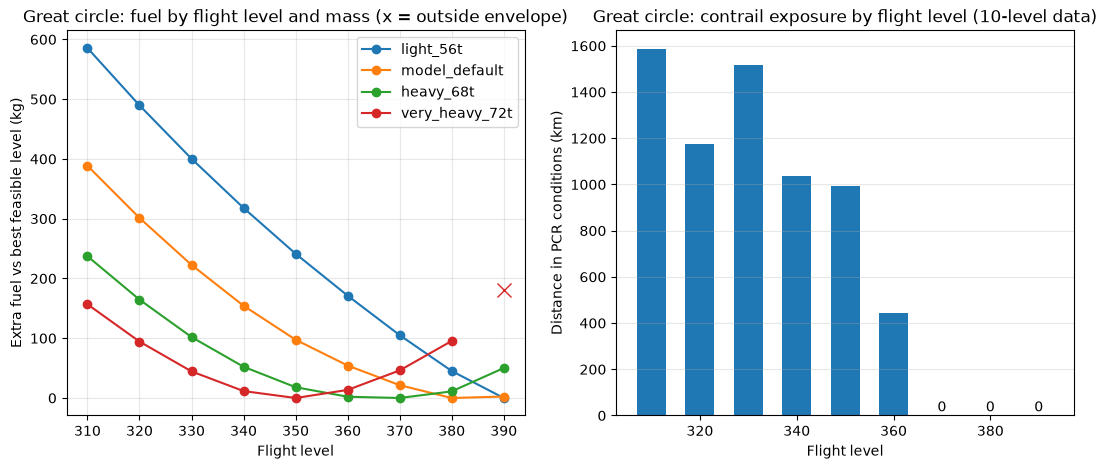

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for mc in MASSES:
    ok = gc_ok[mc]
    rel = gc_fuel[mc] - gc_fuel[mc].where(ok).min()
    line, = ax1.plot(rel.index[ok], rel[ok], "o-", label=mc)
    ax1.plot(rel.index[~ok], rel[~ok], "x", color=line.get_color(), markersize=10)
ax1.set_xlabel("Flight level")
ax1.set_ylabel("Extra fuel vs best feasible level (kg)")
ax1.set_title("Great circle: fuel by flight level and mass (x = outside envelope)")
ax1.grid(alpha=0.3)
ax1.legend()

gcp = pcr_res[pcr_res["offset_km"] == 0].set_index("flight_level")["fine"]
ax2.bar(gcp.index, gcp.values, width=6)
for x, v in gcp.items():
    if v == 0:
        ax2.annotate("0", (x, 0), xytext=(0, 3), textcoords="offset points", ha="center")
ax2.set_xlabel("Flight level")
ax2.set_ylabel("Distance in PCR conditions (km)")
ax2.set_title("Great circle: contrail exposure by flight level (10-level data)")
ax2.grid(alpha=0.3, axis="y")
fig.savefig(fig_dir / "session7_fuel_by_mass_and_exposure.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Route choice by mass under vertical uncertainty

For each mass, the candidates are the feasible FL340–FL390 routes. The three
decision rules from Sessions 5–6 are applied across the 7 vertical scenarios.
"Cheapest always-clean" is the lowest-fuel route that has zero exposure in every
vertical scenario, and its extra fuel is the price of guaranteed avoidance
(within these scenarios).

In [9]:
LAMBDAS = [0.1, 1.0, 10.0]
decisions, summary = [], []
for mc in MASSES:
    fuel = fuel_by_mass[mc]
    cands = [r for r in routes_v if feasible.at[r, mc]]
    min_cand = fuel[cands].idxmin()
    clean = [r for r in cands if pcr_v.loc[r].max() == 0]
    best_clean = min(clean, key=lambda r: fuel[r]) if clean else None
    summary.append({
        "mass_case": mc, "n_candidates": len(cands),
        "min_fuel_route": min_cand, "its_pcr_base_km": pcr_v.at[min_cand, "base"],
        "its_pcr_worst_km": pcr_v.loc[min_cand].max(),
        "cheapest_always_clean": best_clean,
        "extra_fuel_for_always_clean_kg": (fuel[best_clean] - fuel[min_cand]) if best_clean else np.nan,
    })
    for lam in LAMBDAS:
        d = choose(pcr_v, fuel, cands, lam)
        d.insert(0, "lambda", lam)
        d.insert(0, "mass_case", mc)
        decisions.append(d)

summary = pd.DataFrame(summary)
decisions = pd.concat(decisions, ignore_index=True)
pd.set_option("display.width", 220)
print("Per mass (FL340-FL390 candidates, 7 vertical scenarios):")
print(summary.round(1).to_string(index=False))

disagree = decisions.groupby(["mass_case", "lambda"])["route"].transform("nunique") > 1
n_cases = decisions.groupby(["mass_case", "lambda"]).ngroups
n_dis = int(disagree.groupby([decisions["mass_case"], decisions["lambda"]]).any().sum())
print(f"\nCases where the rules disagree: {n_dis} of {n_cases}")
print(decisions[disagree].round(1).to_string(index=False))

summary.to_csv(results_dir / "session7_summary_by_mass.csv", index=False)
decisions.to_csv(results_dir / "session7_robust_decisions.csv", index=False)

Per mass (FL340-FL390 candidates, 7 vertical scenarios):
     mass_case  n_candidates min_fuel_route  its_pcr_base_km  its_pcr_worst_km cheapest_always_clean  extra_fuel_for_always_clean_kg
     light_56t            30      GC0_FL390              0.0               0.0             GC0_FL390                             0.0
 model_default            30      GC0_FL380              0.0             400.2             GC0_FL390                             2.5
     heavy_68t            30      GC0_FL370              0.0             993.6             GC0_FL390                            50.1
very_heavy_72t            25      GC0_FL350            993.6            1518.0                   NaN                             NaN

Cases where the rules disagree: 9 of 12
     mass_case  lambda          rule       route  fuel_kg  pcr_base_km  pcr_worst_km worst_scenario  max_regret_kg  extra_fuel_vs_det_kg
 model_default     0.1 deterministic   GC0_FL380   4922.0          0.0         400.2          up600 

## 6. Fuel discrepancy and correction to Sessions 4–6

For the same route, the new fuel code gave about 2.7% less fuel than Session 4. The first cell checks whether that comes from the finer temperature data or from the code, by running the new fuel code on Session 4's 5-level temperatures. The difference remained, which traced it to a bug in the Session 4 method.

In [10]:
check = fuel_table(res_base["coarse"], config.AIRCRAFT, config.CRUISE_SPEED_MS, {"model_default": None})
check = check.set_index("route")["fuel_kg"]
diff = (check - m4.loc[check.index, "fuel_kg"])
print("New fuel code with 5-level temperatures vs Session 4 (kg):")
print(diff.describe().round(3))
print("\nGC0_FL380: Session 4", round(m4.at["GC0_FL380", "fuel_kg"], 1),
      "| new code, 5-level temps", round(check["GC0_FL380"], 1),
      "| new code, 10-level temps", round(fuel_by_mass.at["GC0_FL380", "model_default"], 1))

New fuel code with 5-level temperatures vs Session 4 (kg):
count     40.000
mean     -92.686
std       64.597
min     -171.131
25%     -143.476
50%     -113.177
75%      -52.861
max       31.493
Name: fuel_kg, dtype: float64

GC0_FL380: Session 4 5060.7 | new code, 5-level temps 4918.5 | new code, 10-level temps 4922.0


The cause: PCR attaches its assumed engine efficiency (0.3) to its output as an attribute, and the PS fuel model used that fixed value instead of computing efficiency itself. Fuel in Sessions 4–6 was therefore off by −171 to +31 kg depending on the route; contrail exposure was unaffected. The code is fixed and covered by a test. Below, Session 4's routes are re-fuelled from their saved temperatures and the Session 4–6 decisions are recomputed.

In [11]:
# Correct fuel for the 40 Session 4 routes, from their saved along-track temperatures
s4_tracks_df = pd.read_csv(results_dir / "session4_routes_along_track.csv", parse_dates=["time"])
s4_tracks = {r: g.reset_index(drop=True) for r, g in s4_tracks_df.groupby("route", sort=False)}
fuel_fix = fuel_table(s4_tracks, config.AIRCRAFT, config.CRUISE_SPEED_MS, {"model_default": None})
fuel_new = fuel_fix.set_index("route")["fuel_kg"].loc[m4.index]
fuel_old = m4["fuel_kg"]
print("Correction (new - old) kg:", (fuel_new - fuel_old).describe()[["min", "mean", "max"]].round(1).to_dict())

m4c = m4.copy()
m4c["fuel_kg"] = fuel_new
m4c["extra_fuel_kg"] = fuel_new - fuel_new.min()
print("\nMinimum-fuel route: old", fuel_old.idxmin(), "| corrected", fuel_new.idxmin())
print("\nGreat circle, extra fuel vs best level (kg):")
gc_cmp = pd.DataFrame({"old": (fuel_old - fuel_old.min()), "corrected": m4c["extra_fuel_kg"]})
print(gc_cmp[m4["offset_km"] == 0].assign(FL=m4["flight_level"]).set_index("FL").round(0))

for ceiling in [360, 340]:
    allowed = m4c[m4c["flight_level"] <= ceiling].copy()
    allowed["route"] = allowed.index
    f = pareto_with_marginal(allowed)
    f["extra_fuel_pct"] = 100 * f["extra_fuel_vs_min_kg"] / f["fuel_kg"].iloc[0]
    print(f"\nCorrected Pareto front, ceiling FL{ceiling}:")
    print(f[["pcr_km", "fuel_kg", "extra_fuel_vs_min_kg", "extra_fuel_pct", "marginal_kg_per_km_avoided"]].round(2).to_string())
fuel_fix.to_csv(results_dir / "session7_session4_fuel_corrected.csv", index=False)

Correction (new - old) kg: {'min': -171.1, 'mean': -92.7, 'max': 31.5}

Minimum-fuel route: old GC0_FL380 | corrected GC0_FL380

Great circle, extra fuel vs best level (kg):
       old  corrected
FL                   
310  223.0      392.0
320  182.0      305.0
330  147.0      226.0
340  117.0      158.0
350   88.0       99.0
360   70.0       57.0
370   31.0       19.0
380    0.0        0.0

Corrected Pareto front, ceiling FL360:
             pcr_km  fuel_kg  extra_fuel_vs_min_kg  extra_fuel_pct  marginal_kg_per_km_avoided
route                                                                                         
GC0_FL360     400.2  4975.89                  0.00            0.00                         NaN
NW150_FL360    69.0  5054.78                 78.90            1.59                        0.24
NW300_FL360    41.4  5291.96                316.07            6.35                        8.59

Corrected Pareto front, ceiling FL340:
             pcr_km  fuel_kg  extra_fuel_vs_min_kg 

In [12]:
# Re-run the Session 5 and 6 decision rules with the corrected fuel
pcr5 = pd.read_csv(results_dir / "session5_pcr_by_scenario.csv", index_col="route").loc[m4.index].drop(columns=["boost"])
pcr6 = pd.read_csv(results_dir / "session6_pcr_by_displacement.csv", index_col="route").loc[m4.index]
pcr_all = pd.concat([pcr5, pcr6.drop(columns=["base"])], axis=1)

rows = []
for label, table in [("humidity (S5)", pcr5), ("displacement (S6)", pcr6), ("all (S5+S6)", pcr_all)]:
    for ceiling in [380, 360, 340]:
        cands = list(m4.index[m4["flight_level"] <= ceiling])
        for lam in [0.1, 1.0, 10.0]:
            old = choose(table, fuel_old, cands, lam).set_index("rule")["route"]
            new = choose(table, fuel_new, cands, lam).set_index("rule")
            rows.append({"set": label, "ceiling": ceiling, "lambda": lam,
                         **{f"{r}_old": old[r] for r in old.index},
                         **{f"{r}_new": new.at[r, "route"] for r in new.index},
                         "worst_case_extra_fuel_new": new.at["worst_case", "extra_fuel_vs_det_kg"]})
redo = pd.DataFrame(rows)
cols_old = ["deterministic_old", "worst_case_old", "min_regret_old"]
cols_new = ["deterministic_new", "worst_case_new", "min_regret_new"]
redo["choice_changed"] = (redo[cols_old].values != redo[cols_new].values).any(axis=1)
redo["rules_disagree_new"] = redo[cols_new].nunique(axis=1) > 1
print(f"Cases where any chosen route changed: {redo['choice_changed'].sum()} of {len(redo)}")
print(f"Cases where the rules disagree (corrected): {redo['rules_disagree_new'].sum()} of {len(redo)}")
pd.set_option("display.width", 250)
print(redo[redo["choice_changed"] | redo["rules_disagree_new"]].round(1).to_string(index=False))
redo.to_csv(results_dir / "session7_session5_6_decisions_corrected.csv", index=False)

Cases where any chosen route changed: 0 of 27
Cases where the rules disagree (corrected): 2 of 27
              set  ceiling  lambda deterministic_old worst_case_old min_regret_old deterministic_new worst_case_new min_regret_new  worst_case_extra_fuel_new  choice_changed  rules_disagree_new
    humidity (S5)      340     0.1         GC0_FL340    NW150_FL340      GC0_FL340         GC0_FL340    NW150_FL340      GC0_FL340                       85.0           False                True
displacement (S6)      340     1.0       NW150_FL340    NW300_FL340    NW150_FL340       NW150_FL340    NW300_FL340    NW150_FL340                      248.4           False                True


## 7. Summary figures

The two figures used in the project README: the trade-off with corrected fuel, and the margin each flight level has above the moist layer.

In [ ]:
# README figure 1: trade-off with corrected fuel
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for ceiling, color in [(340, "tab:blue"), (350, "tab:orange"), (360, "tab:green")]:
    allowed = m4c[m4c["flight_level"] <= ceiling].copy()
    allowed["route"] = allowed.index
    f = pareto_with_marginal(allowed)
    pct = 100 * f["extra_fuel_vs_min_kg"] / f["fuel_kg"].iloc[0]
    ax.step(pct, f["pcr_km"], where="post", marker="o", color=color,
            label=f"Highest allowed level FL{ceiling}")
    for r, x, y in zip(f.index, pct, f["pcr_km"]):
        ax.annotate(r, (x, y), textcoords="offset points", xytext=(5, 4), fontsize=7)
ax.set_xlabel("Extra fuel vs the cheapest route at that ceiling (%)")
ax.set_ylabel("Distance flown in persistent-contrail conditions (km)")
ax.set_title("Contrail exposure vs extra fuel (A320, corrected fuel, 5-level ERA5)")
ax.grid(alpha=0.3)
ax.legend()
fig.savefig(fig_dir / "trade_off_fronts.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# README figure 2: exposure vs vertical displacement of the weather field
shift_m = pd.Series(VERTICAL_M).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
for r in ["GC0_FL360", "GC0_FL370", "GC0_FL380", "GC0_FL390"]:
    ax.plot(shift_m.values, pcr_v.loc[r, shift_m.index].values, marker="o",
            label=r.replace("GC0_", "Great circle, "))
ax.axvline(0, color="grey", linewidth=0.8, linestyle=":")
ax.set_xlabel("Vertical displacement of the weather field (m; + = moist layer higher)")
ax.set_ylabel("Distance flown in persistent-contrail conditions (km)")
ax.set_title("How much margin each flight level has above the moist layer")
ax.grid(alpha=0.3)
ax.legend()
fig.savefig(fig_dir / "vertical_robustness.png", dpi=150, bbox_inches="tight")
plt.show()

## Results

### Setup

45 routes from (−10°, 45°) to (10°, 55°): 5 lateral offsets (0, ±150, ±300 km) × FL310–FL390, departing 2022-03-01 00:00 UTC at a constant 230 m/s with no wind, A320, ERA5 with no humidity scaling. ERA5 was reloaded on 10 pressure levels (175–300 hPa, every 10 hPa between 190 and 250 hPa), which adds FL390. Vertical scenarios move the whole field up or down by 150, 300 and 600 m; start-of-cruise masses are 56 t, the model estimate (≈64 t), 68 t and 72 t.

### Checks

- The first conversion of the 02:00 hour came back empty. It was caught by the
  missing-value check, deleted from the cache and rebuilt (as in Session 2).
  `load_era5_checked` now does this automatically.
- The 5-level region reproduces Session 4's contrail exposure exactly
  (max difference 0.000000 km).
- 18 automated tests pass (geometry, decision rules, PCR on artificial dry and
  supersaturated atmospheres, field shifts, cache repair, fuel calculation).

### Findings

#### Vertical resolution

FL310–FL340 are identical with 5 or 10 levels (both datasets share the levels
at and below 250 hPa). Higher up, the 5-level data underestimated exposure:

| Route | 5 levels | 10 levels |
|---|---|---|
| GC0_FL350 | 856 km | 994 km |
| NW300_FL350 | 97 km | 179 km |
| GC0_FL360 | 400 km | 442 km |
| SE150_FL370 | 0 km | 55 km |
| SE300_FL370 | 0 km | 414 km |
| all FL380 and FL390 routes | 0 km | 0 km |

With 10 levels, ice supersaturation reaches 210 hPa (2.5% of the region) and
is absent at 200 hPa and above. The earlier claim that every FL370 route was
clean was partly an artefact of interpolating across the tropopause between
225 and 200 hPa.

#### Vertical displacement

The whole field was moved up or down, with temperature and relative humidity
carried with the air.

| Route | Base | +150 m | +300 m | +600 m | −150 m | −300 m | −600 m |
|---|---|---|---|---|---|---|---|
| GC0_FL390 | 0 | 0 | 0 | 0 | 0 | 0 | 0 |
| GC0_FL380 | 0 | 0 | 0 | 400 | 0 | 0 | 0 |
| GC0_FL370 | 0 | 248 | 442 | 994 | 0 | 0 | 0 |
| GC0_FL360 | 442 | 911 | 994 | 1,035 | 248 | 0 | 0 |
| NW150_FL360 | 83 | 221 | 331 | 373 | 14 | 0 | 0 |

FL370 is clean by a margin of less than 150 m, FL380 by 300–600 m, and FL390
by more than 600 m. Only four FL390 routes (all except SE300) are clean in
every vertical scenario.

#### Aircraft mass

Fuel was recomputed for start-of-cruise masses of 56 t, the model's own
estimate (≈64 t), 68 t and 72 t (A320 maximum take-off mass in the model:
73.5 t). At 72 t, FL390 is outside the flight envelope.

| Start mass | Minimum-fuel route | Its exposure (base) | Its worst case (vertical) |
|---|---|---|---|
| 56 t | GC0_FL390 (4,387 kg) | 0 km | 0 km |
| ≈64 t | GC0_FL380 (4,922 kg) | 0 km | 400 km |
| 68 t | GC0_FL370 (5,232 kg) | 0 km | 994 km |
| 72 t | GC0_FL350 (5,503 kg) | 994 km | 1,518 km |

The heavier the aircraft, the lower its best cruise level and the closer it
sits to, or inside, the moist layer. A near-full aircraft faces a contrail
trade-off without any air traffic control restriction.

#### Robust choice under vertical uncertainty

Candidates: feasible FL340–FL390 routes; 7 vertical scenarios; λ = 0.1, 1
and 10 kg per km of PCR flight.

- **The rules disagree in 9 of 12 cases**, compared with 1 of 9 for humidity
  scaling (Session 5) and 1 of 18 for horizontal and timing shifts (Session 6).
  The deterministic rule picks the cheapest level that looks clean; robust
  rules climb higher or detour to leave a margin.
- **Price of robustness:**
  - ≈64 t: GC0_FL390 instead of FL380, +2.5 kg (0.05%).
  - 68 t: GC0_FL390 instead of FL370, +50 kg (≈1%).
  - 72 t: NW150_FL380 instead of GC0_FL370 at λ = 1, +125 kg (≈2.2%), worst
    case 83 km instead of 994 km. No route is clean in every scenario.
- **Ignoring vertical uncertainty can be costly.** At 68 t and λ = 10, the
  deterministic choice has a maximum regret of ≈9,900 kg-equivalent; the
  robust choice costs 50 kg.

### Interpretation

Uncertainty in the height of the moist layer is the one that changes route
choices. For this flight, a robust plan climbs to FL390 where the aircraft can,
for 0–1% extra fuel. A near-full aircraft cannot, and the robust plan combines
FL380 with a sideways detour for about 2% extra fuel.

### Corrections

**Vertical shift.** A first version kept specific humidity fixed while changing
pressure, which also dried the field when moving it up (≈9% at 600 m). Those
results (`vertical_*`, not `vertical_v2_*`) were discarded; a test now checks
that relative humidity is preserved.

**Fuel in Sessions 4–6.** PCR attaches its assumed engine efficiency (0.3) to its output, and the PS
fuel model used that fixed value instead of computing its own. Sessions 4–6
fuel was off by −171 to +31 kg per route; contrail exposure was unaffected.
The code is fixed and covered by a test. Recomputed from the saved
temperatures:

- The minimum-fuel route is unchanged (GC0_FL380).
- With a ceiling of FL360, the 150 km north-west detour cuts exposure by 83%
  for **+79 kg (1.6%)**, not 1.4%. With FL340, it cuts 64% for +85 kg (1.7%).
- **No route chosen in Sessions 5–6 changes** (0 of 27 cases), and the rules
  still disagree in the same 2 cases.
- The corrected FL340 front is not convex: NW150_FL320 costs 3.68 kg/km
  avoided, more than the next step (1.74 kg/km), so a weighted objective never
  selects it.

### Limitations

- Cruise only: the extra climb fuel to reach higher levels is not included,
  which favours high levels.
- Constant true airspeed rather than constant Mach; no wind.
- Vertical shifts move the whole column rigidly; real errors also reshape it.
- Shift sizes (150–600 m) are sensitivity cases, not estimates of ERA5 error.
- One flight, one date, one departure time.